# Aula 10 - Regressão Linear

## Motivação

Um banco precisa estimar o valor das casas de um bairro antes de aprovar
um lote de financiamentos. Não existe avaliação recente desse bairro, só
dados do censo: a renda das famílias, a idade das casas, o número de
cômodos, a população. Temos os mesmos dados para outros 20 mil bairros.
Dá para construir, a partir deles, uma regra que estime o valor de um
bairro que ainda não vimos? E como saber, antes de usar essa regra, o
quanto ela vai errar?

Até aqui, o curso fez perguntas de inferência: uma diferença ou uma
associação observada na amostra é real ou fruto do acaso? Esta aula abre
o bloco de aprendizado de máquina, e a pergunta muda de natureza. Saber
que renda e valor estão relacionados já não basta. Queremos usar essa
relação para prever, e um modelo de previsão se julga pelo erro que
comete em dados novos, não nos dados com que aprendeu.

Começamos pela regressão linear simples, da correlação até a reta e o
seu erro. Em seguida, mostramos por que o erro medido nos próprios dados
de ajuste engana e montamos um protocolo de validação, com teste cego e
validação cruzada. A última parte trata da regressão múltipla e do
diagnóstico pelos resíduos e termina com um panorama da regularização e
de outras famílias de modelos de regressão.

> Quanto o modelo vai errar em casas que ele nunca viu?

## Objetivos de aprendizagem

Ao final deste roteiro, você será capaz de:

1.  Calcular e interpretar o intercepto e a inclinação de uma regressão
    linear simples.
2.  Medir o erro de um modelo com MAE, RMSE e $R^2$ e compará-lo com um
    modelo de referência.
3.  Explicar por que o erro de treino é otimista e aplicar o protocolo
    de teste cego com validação cruzada de 5 dobras.
4.  Ajustar e comparar uma regressão linear múltipla nas mesmas dobras,
    interpretando seus coeficientes.
5.  Diagnosticar um modelo pelos gráficos de resíduos.
6.  Explicar o funcionamento da regularização (Ridge, Lasso e
    ElasticNet) e reconhecer a mesma ideia em outros modelos de IA.

> **Como usar este roteiro**
>
> A base California Housing está salva em `california-housing/data/`.
> Ela também pode ser baixada com
> `sklearn.datasets.fetch_california_housing`, mas a cópia local garante
> que todos usem exatamente os mesmos dados. Esta aula usa o
> scikit-learn pela primeira vez. Se ele ainda não estiver no seu
> ambiente, instale-o com `pip install scikit-learn`.

# 1. Preparando o ambiente

Começamos pelas bibliotecas. Do scikit-learn vêm as ferramentas de
partição dos dados, os modelos, as etapas de pré-processamento e as
métricas de erro:

In [1]:
# Importa as bibliotecas e define o tema dos gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from scipy import stats
from scipy.interpolate import CubicSpline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    KFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="colorblind")

## 1.1 Conhecendo a base

A base California Housing vem do censo norte-americano de 1990. Cada
linha não é uma casa, e sim um grupo de quarteirões (*block group*), a
menor unidade geográfica para a qual o censo publica dados, com cerca de
600 a 3.000 moradores. No roteiro, chamamos cada linha de “grupo” ou
“bairro”.

A base vem com o scikit-learn. A cópia local em
`california-housing/data/` foi gerada uma única vez com o código abaixo,
que não é executado no roteiro:

In [2]:
# Baixa a base pelo scikit-learn e salva a cópia local
from sklearn.datasets import fetch_california_housing

(
    fetch_california_housing(as_frame=True)
    .frame
    .to_csv("california-housing/data/california_housing.csv", index=False)
)

Daqui em diante, lemos a cópia local:

In [3]:
# Carrega a base de grupos de quarteirões da Califórnia
housing = pd.read_csv("california-housing/data/california_housing.csv")

housing.head()

| Coluna | Significado | Unidade |
|------------------------|------------------------|------------------------|
| `MedInc` | Renda mediana das famílias do grupo | Dezenas de milhares de dólares (US\$ 10 mil) |
| `HouseAge` | Idade mediana das casas | Anos |
| `AveRooms` | Número médio de cômodos por domicílio | Cômodos |
| `AveBedrms` | Número médio de quartos por domicílio | Quartos |
| `Population` | População do grupo | Pessoas |
| `AveOccup` | Número médio de moradores por domicílio | Pessoas |
| `Latitude`, `Longitude` | Posição geográfica do grupo | Graus |
| `MedHouseVal` | Valor mediano das casas, a variável que queremos prever | Centenas de milhares de dólares (US\$ 100 mil) |

Antes de qualquer modelo, inspecionamos a base:

In [4]:
# Resumo das nove colunas
housing_summary = (
    housing
    .describe()
    .T
    .round(2)
)

housing_summary

O resumo traz três detalhes que voltam ao longo da aula. Não há valores
ausentes: as nove colunas têm 20.640 observações, e nada precisará ser
imputado. Há valores extremos. `AveRooms` chega a 141,9 cômodos por
domicílio, e `AveOccup`, a 1.243 moradores por domicílio. São grupos com
poucos domicílios, como alojamentos, presídios ou áreas de veraneio, e
eles deixam as distribuições dessas colunas fortemente assimétricas.

E há tetos. O máximo de `MedHouseVal` é exatamente 5,0, e o de
`HouseAge`, exatamente 52. O censo registrou como “500 mil ou mais” todo
valor acima de US\$ 500 mil e como “52 ou mais” toda idade acima de 52
anos. Dados assim se chamam **censurados**: sabemos que o valor
verdadeiro é pelo menos 5,0, mas não sabemos quanto.

## 1.2 Antes de tudo: o teste cego

Qualquer decisão tomada olhando para os dados que servirão de avaliação
provoca **vazamento**, e a avaliação deixa de medir o desempenho em
dados realmente novos. Para evitar isso, o aprendizado de máquina segue
um protocolo. Logo depois de carregar os dados, separamos uma parte
deles e a guardamos, intocada, até o fim do roteiro.

Essa parte, com 20% das linhas, é o **teste cego**. Os 80% restantes
formam o **conjunto de desenvolvimento**, onde exploramos os dados e
ajustamos e comparamos modelos. O teste cego só será aberto uma vez, no
fim, para medir o desempenho do modelo escolhido.

In [5]:
# Separa 20% das linhas como teste cego, antes de qualquer análise
X = housing.drop(columns="MedHouseVal")
y = housing["MedHouseVal"]

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

dev = X_dev.assign(MedHouseVal=y_dev)

print(f"Desenvolvimento: {len(X_dev)} linhas · Teste cego: {len(X_test)} linhas")

Desenvolvimento: 16512 linhas · Teste cego: 4128 linhas

Daqui em diante, toda exploração usa apenas `dev`, `X_dev` e `y_dev`.

# 2. Recapitulação: o que precisamos lembrar

## 2.1 Da correlação à reta

O coeficiente de correlação de Pearson, $r$, mede o quanto os pontos de
um gráfico de dispersão seguem uma reta. Vai de −1 a +1, não tem unidade
e é simétrico: a correlação entre renda e valor é a mesma que entre
valor e renda.

A média é o valor que minimiza a soma dos quadrados das distâncias aos
dados. Sem nenhuma informação sobre um bairro, o melhor palpite para o
seu valor, nesse sentido, seria a média de todos os bairros. Esse
palpite ingênuo vai servir de referência, porque um modelo só é útil se
errar menos que ele.

## 2.2 Explicar ou prever?

Uma regressão pode servir a dois propósitos, e cada um pede cuidados
próprios:

|  | Inferência | Previsão |
|------------------------|------------------------|------------------------|
| Pergunta | A relação existe? Qual o seu tamanho? | Quanto vale o próximo bairro? |
| Foco | Os coeficientes e sua incerteza | As previsões e seu erro |
| Avaliação | *p*-valor, intervalo de confiança | Erro em dados que o modelo não viu |
| Risco principal | Confundir associação com causa | Confundir erro de treino com erro real |

Os dois usam o mesmo modelo. A previsão, porém, traz uma exigência nova:
o erro precisa ser medido em dados que ficaram fora do ajuste. É disso
que trata esta aula.

## 2.3 O vocabulário do aprendizado de máquina

Alguns termos vão aparecer o tempo todo. No **aprendizado
supervisionado**, o modelo aprende com exemplos cuja resposta é
conhecida; aqui, cada bairro do desenvolvimento traz os atributos e o
valor das casas. Quando a resposta é numérica, como esse valor, o
problema é de **regressão**. Quando é uma categoria, como “sobreviveu”
ou “não sobreviveu”, é de **classificação**.

**Treinar**, ou ajustar, um modelo é encontrar os seus parâmetros a
partir dos dados, o que no scikit-learn se faz com o método `.fit`.
**Prever** é aplicar o modelo treinado a novos atributos, com
`.predict`. E **generalização** é a capacidade de errar pouco em dados
que o modelo nunca viu.

# 3. Regressão linear simples, passo a passo

## 3.1 Olhando para os dados

Começamos pela relação mais intuitiva: bairros de renda mais alta têm
casas mais caras? Antes do modelo, olhamos para a resposta e para a
relação dela com a renda:

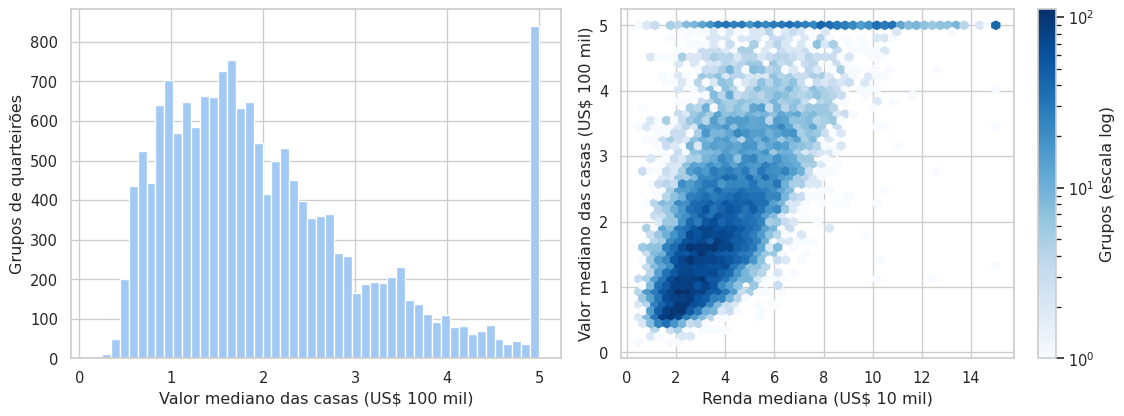

In [6]:
# Distribuição do valor das casas e relação com a renda
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(dev["MedHouseVal"], bins=50, color="#A1C9F4", edgecolor="white")
axes[0].set(xlabel="Valor mediano das casas (US$ 100 mil)",
            ylabel="Grupos de quarteirões")

hexes = axes[1].hexbin(dev["MedInc"], dev["MedHouseVal"], gridsize=45,
                       cmap="Blues", mincnt=1, bins="log")
fig.colorbar(hexes, ax=axes[1], label="Grupos (escala log)")
axes[1].set(xlabel="Renda mediana (US$ 10 mil)",
            ylabel="Valor mediano das casas (US$ 100 mil)")

plt.tight_layout()
plt.show()

In [7]:
# Proporção de grupos no teto de 5,0
capped_share = (dev["MedHouseVal"] >= 5).mean()

print(f"Grupos no teto de 5,0: {capped_share:.1%}")

Grupos no teto de 5,0: 4.9%

A maioria dos bairros vale entre US\$ 100 mil e US\$ 250 mil, e a
distribuição tem uma cauda longa à direita. No fim do histograma, uma
barra isolada reúne cerca de 5% dos grupos: é o teto em 5,0. No painel
da direita, esse teto vira uma linha horizontal de hexágonos que
atravessa todas as faixas de renda. Esses bairros valem “5,0 ou mais”, e
o modelo não tem como saber quanto mais.

O valor sobe com a renda de forma aproximadamente linear. Para uma mesma
renda, porém, há bairros com valores muito diferentes. A renda explica
parte da história, mas não toda.

## 3.2 O que é a “melhor” reta?

Uma reta é descrita por dois números:

$$
\hat{y} = \beta_0 + \beta_1 x
$$

O **intercepto** $\beta_0$ é a altura da reta quando $x = 0$, e a
**inclinação** $\beta_1$ diz quanto $\hat{y}$ muda quando $x$ aumenta em
uma unidade. O chapéu em $\hat{y}$ indica uma previsão, e não o valor
observado $y$.

Em cada bairro, a diferença entre o valor observado e o previsto é o
**resíduo**:

$$
e_i = y_i - \hat{y}_i
$$

Um resíduo positivo indica que o bairro vale mais do que a reta prevê;
um negativo, que vale menos. Entre todas as retas possíveis, o método de
**mínimos quadrados ordinários** (*ordinary least squares*, OLS) escolhe
a que deixa a soma dos quadrados dos resíduos o menor possível:

$$
\text{SQ}_{\text{res}} = \sum_{i=1}^{n} e_i^2 = \sum_{i=1}^{n} (y_i - \beta_0 - \beta_1 x_i)^2
$$

Por que o quadrado? Porque ele impede que resíduos positivos e negativos
se cancelem e dá mais peso aos erros grandes. Há também uma vantagem
prática: a reta ótima tem fórmula fechada, sem tentativa e erro.

## 3.3 Ajustando a reta com o scikit-learn

Não é preciso fazer essa minimização à mão. O scikit-learn faz isso por
nós e organiza todos os modelos em torno da mesma interface, de modo que
o que se aprende com a regressão linear vale para o resto do bloco de
aprendizado de máquina:

In [8]:
# Reta de mínimos quadrados ajustada com o scikit-learn
m1 = LinearRegression()
m1.fit(X_dev[["MedInc"]], y_dev)

print(f"β0 = {m1.intercept_:.4f} · β1 = {m1.coef_[0]:.4f}")

new_incomes = pd.DataFrame({"MedInc": [2, 4, 8]})
m1.predict(new_incomes)

β0 = 0.4446 · β1 = 0.4193

array([1.28327428, 2.12195127, 3.79930524])

O padrão criar → `.fit` → `.predict` se repete em árvores de decisão,
florestas aleatórias, redes neurais e todos os outros modelos do
scikit-learn.

Vamos chamar esta reta de **M1**, o modelo simples, que usa só a renda.
Mais adiante, ela será comparada com o **M2**, que usa seis atributos.

Na regressão simples, a solução da minimização liga a reta à correlação
de Pearson:

$$
\beta_1 = r \cdot \frac{s_y}{s_x}
\qquad\qquad
\beta_0 = \bar{y} - \beta_1 \bar{x}
$$

A inclinação é a correlação convertida para as unidades dos dados. O $r$
diz quão alinhados estão os pontos, e a razão $s_y / s_x$ entre os
desvios-padrão traduz “desvios-padrão de $x$” em “unidades de $y$”. O
intercepto faz a reta passar pelo ponto médio $(\bar{x}, \bar{y})$.

## 3.4 O que a minimização faz

Para ver o que significa minimizar os quadrados, sorteamos 15 bairros e
comparamos os resíduos de duas retas. À esquerda está a reta ajustada
pelo scikit-learn; à direita, uma reta traçada no olho, mais inclinada.
Os segmentos laranja são os resíduos, e o título de cada painel traz o
**erro quadrático médio** (EQM, ou MSE em inglês), a média dos quadrados
dos resíduos:

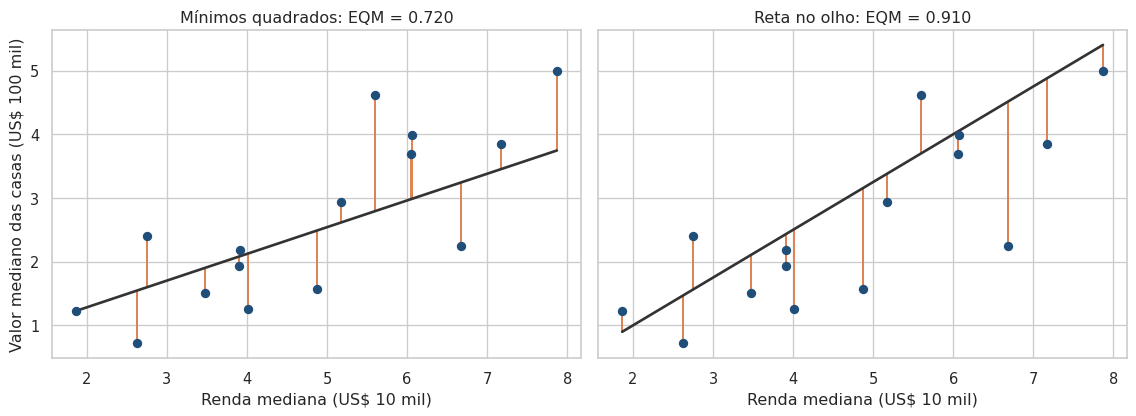

In [9]:
# Resíduos de 15 grupos em relação à reta ajustada e a uma reta no olho
sample = dev.sample(15, random_state=3)
income_grid = pd.DataFrame(
    {"MedInc": np.linspace(sample["MedInc"].min(), sample["MedInc"].max(), 100)}
)

lines = {
    "Mínimos quadrados": lambda df: m1.predict(df[["MedInc"]]),
    "Reta no olho": lambda df: -0.5 + 0.75 * df["MedInc"],
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, predict) in zip(axes, lines.items()):
    fitted = predict(sample)
    ax.vlines(sample["MedInc"], fitted, sample["MedHouseVal"],
              color="#DD8452", linewidth=1.5)
    ax.scatter(sample["MedInc"], sample["MedHouseVal"], color="#1F4E79", zorder=3)
    ax.plot(income_grid["MedInc"], predict(income_grid), color="#333333", linewidth=2)
    mse = mean_squared_error(sample["MedHouseVal"], fitted)
    ax.set(title=f"{name}: EQM = {mse:.3f}", xlabel="Renda mediana (US$ 10 mil)")
axes[0].set_ylabel("Valor mediano das casas (US$ 100 mil)")
plt.tight_layout()
plt.show()

A reta no olho chega mais perto de alguns pontos, como o bairro de renda
mais alta, mas se afasta muito de outros, como o de renda 6,7 e valor
2,2. Elevados ao quadrado, esses resíduos grandes dominam a média. A
reta de mínimos quadrados distribui os erros de modo a minimizar o
total, e foi ajustada com os 16.512 bairros do desenvolvimento, não só
com estes 15.

## 3.5 Interpretando os coeficientes

A reta ajustada é:

$$
\widehat{\text{MedHouseVal}} = 0{,}445 + 0{,}419 \times \text{MedInc}
$$

Pela inclinação, cada unidade a mais de renda mediana, ou seja, US\$ 10
mil a mais por ano, está associada a 0,419 unidade a mais no valor
mediano das casas, cerca de US\$ 41,9 mil. Um bairro com renda de US\$
40 mil tem valor previsto de
$0{,}445 + 0{,}419 \times 4 \approx 2{,}12$, ou US\$ 212 mil.

O intercepto é, geometricamente, o valor previsto para um bairro de
renda zero: US\$ 44,5 mil. Só que nenhum bairro da base tem renda perto
de zero (a menor é 0,5), então esse número é uma extrapolação sem
leitura prática. Ele serve para posicionar a reta, não para ser
interpretado.

Dois cuidados valem para qualquer coeficiente. O primeiro é que ele
descreve associação, e não causa. $\beta_1$ mostra como o valor das
casas varia entre bairros de rendas diferentes. Não diz que aumentar a
renda das famílias de um bairro valorizaria as casas em US\$ 41,9 mil. O
segundo é que a reta foi aprendida com rendas entre 0,5 e 15, e fora
desse intervalo nada garante que a relação continue linear.

> **E o *p*-valor de $\beta_1$?**
>
> A regressão também pode ser lida como um teste de hipóteses, com
> $H_0: \beta_1 = 0$, isto é, sem relação linear entre renda e valor. O
> `stats.linregress` do SciPy devolve, além dos coeficientes, o
> erro-padrão da inclinação e o *p*-valor:
>
> ``` python
> # Inclinação, erro-padrão e p-valor da regressão simples
> slope_test = stats.linregress(dev["MedInc"], dev["MedHouseVal"])
>
> print(f"β1 = {slope_test.slope:.4f} · erro-padrão = {slope_test.stderr:.4f} · "
>       f"p = {slope_test.pvalue:.1e}")
> ```
>
>     β1 = 0.4193 · erro-padrão = 0.0034 · p = 0.0e+00
>
> O teste divide o sinal pelo ruído, e aqui a inclinação é mais de cem
> vezes maior que o seu erro-padrão. O *p*-valor fica praticamente em
> zero, e o teste equivale ao da correlação de Pearson. Ele responde se
> existe relação linear. Com 16 mil bairros, a resposta é sim, sem
> dúvida.
>
> Isso não diz se a reta prevê bem. Um $\beta_1$ altamente significativo
> pode conviver com previsões ruins, e é para essa segunda pergunta que
> servem as métricas da próxima seção.

## 3.6 Medindo o erro

Quanto a reta erra? Três métricas resumem os resíduos, cada uma à sua
maneira:

| Métrica | Fórmula | Leitura |
|------------------------|------------------------|------------------------|
| MAE (erro absoluto médio) | $\frac{1}{n}\sum \lvert e_i \rvert$ | Erro típico, na unidade de $y$. Trata todos os erros igualmente |
| RMSE (raiz do erro quadrático médio) | $\sqrt{\frac{1}{n}\sum e_i^2}$ | Também na unidade de $y$, mas pesa mais os erros grandes. É a métrica que o OLS minimiza |
| $R^2$ (coeficiente de determinação) | $1 - \frac{\text{SQ}_{\text{res}}}{\text{SQ}_{\text{tot}}}$ | Fração da variação de $y$ explicada pelo modelo. Não tem unidade |

No $R^2$, $\text{SQ}_{\text{tot}} = \sum (y_i - \bar{y})^2$ é a soma dos
quadrados dos resíduos do modelo de referência, que prevê sempre a
média. O $R^2$ compara o modelo com esse palpite ingênuo: vale 0 quando
o modelo não erra menos que a média e 1 quando acerta todos os pontos.

O scikit-learn já traz esse modelo de referência pronto. É o
`DummyRegressor`, que ignora os atributos e prevê sempre a média.
Geramos as previsões dele e do M1 nos próprios dados de ajuste:

In [11]:
# Previsões do modelo de referência e do M1 nos próprios dados de ajuste
baseline = DummyRegressor(strategy="mean").fit(X_dev[["MedInc"]], y_dev)

predictions = {
    "Referência (média)": baseline.predict(X_dev[["MedInc"]]),
    "M1 (renda)": m1.predict(X_dev[["MedInc"]]),
}

E calculamos as três métricas para cada um:

In [12]:
# MAE, RMSE e R² de cada modelo
fit_metrics = (
    pd.DataFrame(
        {
            name: {
                "MAE": mean_absolute_error(y_dev, pred),
                "RMSE": root_mean_squared_error(y_dev, pred),
                "R²": r2_score(y_dev, pred),
            }
            for name, pred in predictions.items()
        }
    )
    .T
    .round(4)
)

fit_metrics

Em média, o M1 erra o valor mediano de um bairro em cerca de US\$ 62
mil, para mais ou para menos (MAE de 0,625). O modelo de referência erra
US\$ 91 mil. O RMSE do M1, de 0,84, sai maior que o MAE porque pesa mais
os erros grandes, como os dos bairros no teto de 5,0. Diante do RMSE de
1,16 da referência, a renda reduz o erro típico de US\$ 116 mil para
US\$ 84 mil.

O $R^2$ de 0,48 indica que a renda explica cerca de 48% da variação do
valor entre bairros. Os outros 52% ficam nos resíduos. A referência tem
$R^2 = 0$ por definição. Na regressão simples, o $R^2$ é exatamente o
quadrado da correlação de Pearson entre $x$ e $y$:
$0{,}691^2 \approx 0{,}477$.

Esses números têm um problema. Foram calculados nos mesmos bairros
usados para ajustar a reta, como uma prova cujas respostas o modelo já
viu. A próxima seção mostra por que isso é perigoso.

# 4. Por que o erro de treino engana

## 4.1 Um modelo que decora

Pense em um aluno que se prepara estudando só as questões das provas
anteriores. Se ele entende a matéria, vai bem também em questões novas.
Se apenas decora as respostas, tira nota máxima nas provas antigas e se
perde na primeira questão diferente. A nota nas provas antigas não
separa um aluno do outro. Só uma prova nova faz isso.

Com modelos acontece o mesmo. Chamamos de **erro de treino** o erro
medido nos bairros usados no ajuste, e de **erro de validação** o erro
medido em bairros que ficaram de fora. Suponha que houvesse só 20
bairros para treinar. Uma reta passa entre eles sem tocar a maioria e
erra um pouco em cada um. Uma curva flexível o bastante, cheia de
dobras, consegue passar exatamente por cima dos 20 pontos, e o erro de
treino vai a zero. Parece perfeita, mas essa curva aprendeu também o
ruído daqueles 20 bairros, as particularidades que não se repetem.
Diante de um bairro novo, ela oscila entre os pontos que memorizou e dá
previsões absurdas, sobretudo fora da faixa de renda que viu no treino.

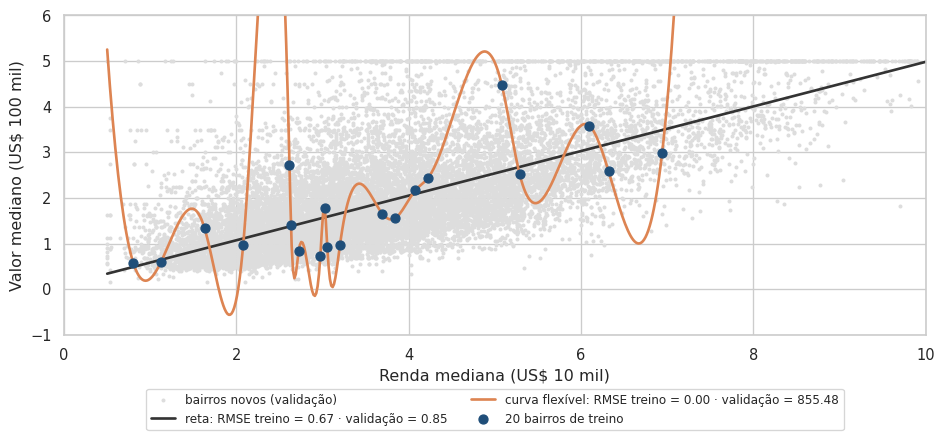

Na figura, a reta passa no meio da nuvem e erra quase o mesmo nos 20
bairros de treino e nos bairros novos. A curva laranja acerta em cheio
cada um dos 20 pontos, com erro de treino zero, mas se contorce entre
eles. Em alguns trechos, como entre as rendas 2 e 2,6, chega a sair do
gráfico, e depois do último ponto, perto da renda 7, dispara de vez. Nos
bairros novos, o seu erro é cerca de mil vezes maior que o da reta.

Esse comportamento se chama **sobreajuste** (*overfitting*): o modelo
aprende o ruído da amostra de treino junto com o padrão, e o ruído não
se repete em dados novos. O contrário, um modelo simples demais para
captar o padrão, é o **subajuste** (*underfitting*). A tabela compara os
três cenários:

| Modelo | Erro de treino | Erro de validação | Diagnóstico |
|------------------|------------------|------------------|------------------|
| Simples demais | Alto | Alto | Subajuste: não captou o padrão |
| Na medida | Moderado | Moderado, próximo do de treino | Generaliza bem |
| Flexível demais | Muito baixo | Alto | Sobreajuste: decorou o ruído |

À medida que o modelo ganha flexibilidade, o erro de treino só cai. O de
validação cai até certo ponto e, a partir daí, volta a subir. O
equilíbrio entre os dois extremos é o **dilema viés-variância**. Modelos
simples erram de forma sistemática, sempre para o mesmo lado em certas
regiões (viés). Modelos flexíveis erram de forma instável: troque os 20
bairros de treino, e a curva muda por completo (variância).

O erro de treino, portanto, não serve para escolher modelos, porque
sempre premia o mais flexível. É preciso medir o erro em dados que o
modelo não viu.

## 4.2 Validação cruzada com 5 dobras

O teste cego já está guardado. Por que não usá-lo para comparar modelos?
Para responder, vale separar as três tarefas que os dados cumprem em um
projeto de aprendizado de máquina:

| Conjunto | Pergunta que responde | O que se decide com ele |
|------------------------|------------------------|------------------------|
| Treino | Quais coeficientes descrevem melhor estes dados? | Os parâmetros do modelo, pelo `.fit` |
| Validação | Qual modelo, ou qual configuração, erra menos em dados novos? | A escolha entre modelos, atributos e hiperparâmetros |
| Teste | Quanto o modelo escolhido vai errar na prática? | Nada: ele só mede o resultado final |

Cada vez que comparamos dois modelos, testamos um atributo a mais ou
ajustamos uma configuração, olhamos o erro de **validação** e ficamos
com a opção que errou menos. O **teste** vem depois, quando não há mais
nada a decidir, e serve para estimar o erro do modelo que saiu dessa
escolha.

A ordem importa porque toda escolha feita olhando um conjunto de dados
deixa o erro medido nele otimista. O erro de um modelo em uma amostra
tem uma parte que reflete a sua qualidade e outra que é sorte, ou seja,
o quanto aquela amostra em particular favoreceu o modelo. Ao comparar
vários modelos e ficar com o que errou menos, escolhemos, em parte, o
que teve mais sorte naquela amostra. Com dois modelos, o efeito é
pequeno. Com dezenas, ele cresce, pelo mesmo motivo do problema dos
múltiplos testes: quanto mais comparações, maior a chance de algum
resultado parecer bom só por acaso.

Por isso, o erro do modelo vencedor no conjunto de validação tende a ser
um pouco melhor do que o erro que ele terá na prática. Se o teste também
participasse da escolha, sofreria do mesmo viés e deixaria de ser uma
medida honesta. Mantido intocado até o fim, ele é o único conjunto em
que o modelo escolhido é avaliado sem que nenhuma decisão tenha sido
tomada a seu favor.

É como estudar com simulados: eles servem para descobrir onde você
precisa melhorar, mas a nota que vale é a da prova, que você não viu
antes.

Resta um problema prático. Se reservarmos mais uma fatia fixa dos dados
só para validar, sobram menos bairros para treinar, e a escolha passa a
depender de quais bairros caíram nessa fatia. A saída é criar avaliações
dentro do próprio desenvolvimento, reaproveitando os mesmos dados.

A **validação cruzada com $k$ dobras** (*k-fold cross-validation*)
divide o desenvolvimento em $k$ partes de tamanho parecido. Em cada
rodada, uma parte faz o papel de validação e as outras $k - 1$, o de
treino. Ao fim das $k$ rodadas, cada bairro terá sido usado exatamente
uma vez para validar:

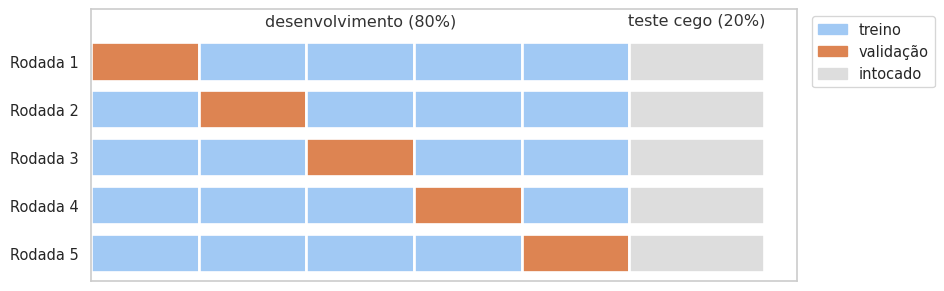

In [15]:
# Esquema do protocolo: teste cego e cinco rodadas de validação cruzada
fig, ax = plt.subplots(figsize=(10, 3.2))
for k in range(5):
    for j in range(5):
        ax.barh(k, 0.16, left=j * 0.16, color="#DD8452" if j == k else "#A1C9F4",
                edgecolor="white", linewidth=2)
    ax.barh(k, 0.2, left=0.8, color="#DDDDDD", edgecolor="white", linewidth=2)
ax.text(0.9, -0.75, "teste cego (20%)", ha="center", color="#333333")
ax.text(0.4, -0.75, "desenvolvimento (80%)", ha="center", color="#333333")
ax.set(yticks=range(5), yticklabels=[f"Rodada {k + 1}" for k in range(5)],
       xticks=[], ylim=(4.6, -1.1))
ax.legend(handles=[Patch(color="#A1C9F4", label="treino"),
                   Patch(color="#DD8452", label="validação"),
                   Patch(color="#DDDDDD", label="intocado")],
          loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(False)
plt.tight_layout()
plt.show()

O resultado são cinco medidas de erro, e não uma. A média delas estima o
erro em dados novos; o desvio-padrão mostra o quanto essa estimativa
depende de quais bairros caíram em cada dobra. No scikit-learn, `KFold`
define as dobras e `cross_validate` executa as cinco rodadas:

In [16]:
# Validação cruzada com 5 dobras para o M1
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2"}

cv_m1 = cross_validate(LinearRegression(), X_dev[["MedInc"]], y_dev, cv=kfold,
                       scoring=scoring, return_train_score=True)

folds_m1 = pd.DataFrame(
    {
        "r2_treino": cv_m1["train_r2"],
        "r2_validacao": cv_m1["test_r2"],
        "rmse_validacao": -cv_m1["test_rmse"],
    },
    index=pd.RangeIndex(1, 6, name="dobra"),
)

folds_m1.round(4)

O resumo das cinco dobras:

In [17]:
# Média e desvio-padrão das métricas nas cinco dobras
summary_m1 = (
    folds_m1
    .agg(["mean", "std"])
    .round(4)
)

summary_m1

O $R^2$ médio de validação fica em torno de 0,48, e o RMSE, em 0,84,
praticamente os valores obtidos nos dados de ajuste. As médias do $R^2$
de treino e de validação coincidem em 0,477. Ao contrário da curva que
decora os 20 bairros, uma reta com um único atributo e 13 mil bairros
por treino não tem flexibilidade para decorar nada, e fica longe do
sobreajuste.

As dobras também são estáveis. O desvio-padrão do $R^2$ passa pouco de
0,01, e o desempenho quase não muda com a divisão dos bairros.

## 4.3 Estabilidade dos coeficientes nas dobras

A validação cruzada também mostra se o próprio modelo muda de uma dobra
para outra. Ajustamos uma reta em cada conjunto de treino e desenhamos
as cinco juntas. Para comparar, repetimos o procedimento com só 100
bairros sorteados do desenvolvimento:

In [18]:
# Cinco retas de treino em cada base: todos os bairros e apenas 100 bairros
bases = {"16.512 bairros": dev, "100 bairros": dev.sample(100, random_state=0)}

fold_models = {
    label: cross_validate(LinearRegression(), data[["MedInc"]], data["MedHouseVal"],
                          cv=kfold, return_estimator=True)["estimator"]
    for label, data in bases.items()
}

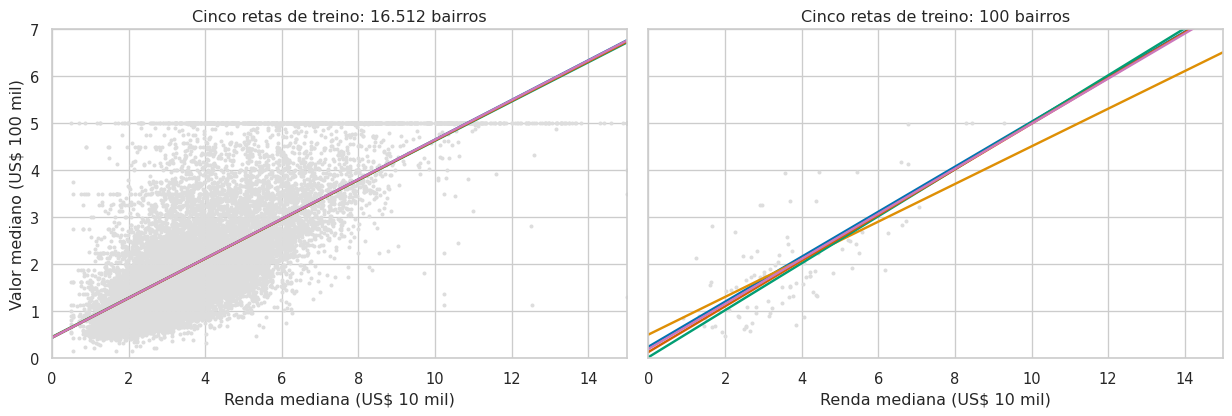

In [19]:
# Uma reta por dobra, desenhada sobre cada base
income_grid = pd.DataFrame({"MedInc": np.linspace(0, 15, 100)})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (label, data) in zip(axes, bases.items()):
    ax.scatter(data["MedInc"], data["MedHouseVal"], color="#DDDDDD", s=4)
    for fold_model in fold_models[label]:
        ax.plot(income_grid["MedInc"], fold_model.predict(income_grid), linewidth=1.8)
    ax.set(title=f"Cinco retas de treino: {label}", xlabel="Renda mediana (US$ 10 mil)",
           xlim=(0, 15), ylim=(0, 7))
axes[0].set_ylabel("Valor mediano (US$ 100 mil)")
plt.tight_layout()
plt.show()

A tabela mostra o menor e o maior valor de cada coeficiente entre as
cinco dobras:

In [20]:
# Menor e maior coeficiente entre as cinco dobras de cada base
coef_range = (
    pd.DataFrame(
        [
            {"base": label, "beta_0": model.intercept_, "beta_1": model.coef_[0]}
            for label, models in fold_models.items()
            for model in models
        ]
    )
    .groupby("base")[["beta_0", "beta_1"]]
    .agg(["min", "max"])
    .round(4)
)

coef_range

Com 16.512 bairros, as cinco retas quase se sobrepõem, e a inclinação
varia só entre 0,417 e 0,421. Com 100 bairros, o feixe se abre, e a
inclinação de cada dobra passa a depender bastante de quais bairros
caíram no treino. Quanto maior a amostra, menos a estimativa varia de
uma amostra para outra.

Com a base completa, o M1 é estável, mas limitado. Tem pouca variância e
muito viés, porque a renda, sozinha, deixa metade da variação sem
explicação.

# 5. Regressão linear múltipla

> **Cenário**
>
> O M1 mostra uma associação forte entre renda e valor, mas ignora as
> características das casas, como idade e número de cômodos, e a
> densidade dos bairros. Incluir esses atributos reduz o erro em dados
> novos? E o ganho visto na validação cruzada se mantém no teste cego?
>
> -   M1 (simples): `MedInc`.
> -   M2 (múltiplo): `MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`,
>     `Population` e `AveOccup`.

A regressão múltipla estende a reta para vários atributos:

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p
$$

Com dois atributos, o modelo vira um plano. Com mais, vira um
hiperplano, que não dá para desenhar, mas segue a mesma lógica. Os
coeficientes continuam sendo escolhidos por mínimos quadrados, e o
código só muda na lista de colunas.

## 5.1 O M2 nas mesmas dobras

Para que a comparação seja justa, o M2 é avaliado nas mesmas cinco
dobras do M1, o que se garante reutilizando o objeto `kfold`. Em cada
rodada, os dois modelos são treinados e validados nos mesmos bairros, e
as diferenças passam a vir só dos modelos, não da sorte da divisão. É
uma comparação pareada:

In [21]:
# M2: seis atributos, avaliados nas mesmas cinco dobras do M1
features_m2 = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup"]

cv_m2 = cross_validate(LinearRegression(), X_dev[features_m2], y_dev, cv=kfold,
                       scoring=scoring, return_train_score=True)

comparison = pd.DataFrame(
    {
        "M1_r2": cv_m1["test_r2"],
        "M2_r2": cv_m2["test_r2"],
        "M1_rmse": -cv_m1["test_rmse"],
        "M2_rmse": -cv_m2["test_rmse"],
    },
    index=pd.RangeIndex(1, 6, name="dobra"),
)

A média e o desvio-padrão de cada métrica nas cinco dobras:

In [22]:
# Média e desvio-padrão de M1 e M2 nas cinco dobras
comparison_summary = (
    comparison
    .agg(["mean", "std"])
    .round(4)
)

comparison_summary

O gráfico liga, em cada dobra, o desempenho do M1 ao do M2:

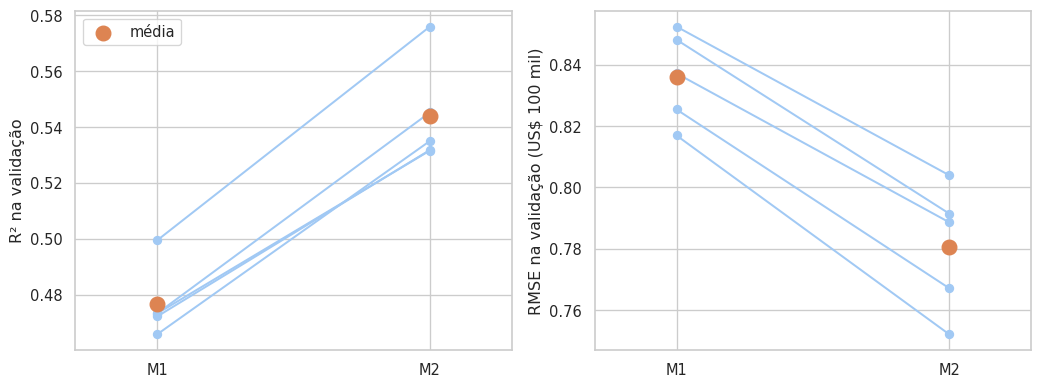

In [23]:
# Desempenho pareado de M1 e M2 em cada dobra
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for ax, metric, label in zip(axes, ["r2", "rmse"],
                             ["R² na validação", "RMSE na validação (US$ 100 mil)"]):
    values = comparison[[f"M1_{metric}", f"M2_{metric}"]]
    for _, row in values.iterrows():
        ax.plot([0, 1], row.to_numpy(), color="#A1C9F4", marker="o", zorder=2)
    ax.scatter([0, 1], values.mean(), color="#DD8452", s=120, zorder=3, label="média")
    ax.set(xticks=[0, 1], xticklabels=["M1", "M2"], xlim=(-0.3, 1.3), ylabel=label)
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

O M2 vence em todas as cinco dobras. O $R^2$ sobe de cerca de 0,48 para
0,54, e o RMSE cai de 0,84 para 0,78, o que, em dinheiro, reduz o erro
típico em cerca de US\$ 6 mil por bairro. As linhas são quase paralelas:
a dobra mais difícil para o M1 também é a mais difícil para o M2, e o
ganho se repete em todas.

## 5.2 Lendo os coeficientes

Ajustamos o M2 em todo o desenvolvimento para examinar os coeficientes.
Como os atributos têm unidades muito diferentes, de pessoas a cômodos,
ajustamos também uma versão com os atributos padronizados pelo
`StandardScaler`. Nela, cada coeficiente indica a mudança em $y$ quando
o atributo aumenta um desvio-padrão, e os coeficientes ficam comparáveis
entre si:

In [24]:
# Coeficientes do M2 em unidades originais e padronizadas
m2 = LinearRegression().fit(X_dev[features_m2], y_dev)
m2_scaled = make_pipeline(StandardScaler(), LinearRegression()).fit(
    X_dev[features_m2], y_dev
)

coefficients = (
    pd.DataFrame(
        {
            "original": m2.coef_,
            "padronizado": m2_scaled[-1].coef_,
            "correlacao_com_y": X_dev[features_m2].corrwith(y_dev),
        },
        index=features_m2,
    )
    .round(4)
)

coefficients

Na regressão múltipla, cada coeficiente mede a associação de um atributo
com $y$ **mantidos constantes os demais atributos do modelo**. É aí que
ela difere da regressão simples.

Veja `MedInc`. Entre bairros com a mesma idade das casas, o mesmo número
de cômodos e de quartos, a mesma população e a mesma ocupação, US\$ 10
mil a mais de renda estão associados a US\$ 54,6 mil a mais no valor. É
o atributo de maior peso: um desvio-padrão de renda equivale a cerca de
1,04 unidade de valor.

Com os demais atributos fixos, casas mais antigas (`HouseAge`) estão
associadas a valores um pouco maiores. Uma explicação possível é que
bairros antigos tendem a ser mais centrais, mas os dados não permitem
confirmar. Já o coeficiente original de `Population` parece zero, o que
é efeito da unidade: uma pessoa a mais no bairro é uma mudança
minúscula. Na escala padronizada, o efeito é pequeno, mas não nulo.
Tamanhos de coeficientes, por isso, só devem ser comparados na escala
padronizada.

O coeficiente de `AveRooms` traz uma surpresa. É negativo, embora a
correlação de `AveRooms` com o valor seja positiva. Mais cômodos
desvalorizariam as casas? Vejamos como o coeficiente muda à medida que
outros atributos entram no modelo:

In [25]:
# Coeficiente de AveRooms em três especificações diferentes
specs = {
    "só AveRooms": ["AveRooms"],
    "AveRooms + MedInc": ["AveRooms", "MedInc"],
    "M2 (seis atributos)": features_m2,
}

for name, cols in specs.items():
    coefs = pd.Series(LinearRegression().fit(X_dev[cols], y_dev).coef_, index=cols)
    print(f"{name:<20} β(AveRooms) = {coefs['AveRooms']:+.4f}")

rooms_corr = X_dev[["AveBedrms", "MedInc"]].corrwith(X_dev["AveRooms"])

print(f"\nCorrelação AveRooms × AveBedrms = {rooms_corr['AveBedrms']:.2f}")
print(f"Correlação AveRooms × MedInc    = {rooms_corr['MedInc']:.2f}")

só AveRooms          β(AveRooms) = +0.0768
AveRooms + MedInc    β(AveRooms) = -0.0402
M2 (seis atributos)  β(AveRooms) = -0.2239

Correlação AveRooms × AveBedrms = 0.84
Correlação AveRooms × MedInc    = 0.34

Sozinho, `AveRooms` tem coeficiente positivo: bairros com casas maiores
valem mais. Parte disso, porém, acontece porque casas maiores ficam em
bairros mais ricos. Quando a renda entra no modelo, o coeficiente fica
negativo. Entre bairros da mesma renda, ter mais cômodos deixa de estar
associado a valores maiores, e parte do efeito aparente dos cômodos se
revela efeito da renda. Esse é o **viés de variável omitida**: quando um
atributo relevante fica de fora, os coeficientes dos outros absorvem a
sua influência.

Com `AveBedrms`, o coeficiente fica ainda mais negativo. Cômodos e
quartos têm correlação de 0,84, e quando um cresce o outro quase sempre
cresce junto. Manter os quartos constantes e aumentar os cômodos é raro
nos dados, e o modelo divide o efeito entre os dois de forma instável,
com um coeficiente negativo e o outro fortemente positivo. É a
**multicolinearidade**.

Ela não piora as previsões, porque o efeito combinado dos dois atributos
continua bem estimado. Piora a interpretação: os coeficientes
individuais ficam instáveis e podem ter sinais contraintuitivos. Para
prever, isso é tolerável; para explicar, é um alerta. A regularização,
apresentada adiante, é uma forma de lidar com o problema.

## 5.3 Diagnóstico pelos resíduos

As métricas resumem o erro em um número. Os resíduos mostram onde e como
o modelo erra. Para não avaliar o modelo em dados que ele viu, usamos
`cross_val_predict`, e cada bairro recebe a previsão do modelo treinado
nas outras quatro dobras.

In [26]:
# Previsões fora da dobra para todo o conjunto de desenvolvimento
oof_m2 = cross_val_predict(LinearRegression(), X_dev[features_m2], y_dev, cv=kfold)
residuals_m2 = y_dev - oof_m2

print(f"Previsões negativas: {(oof_m2 < 0).sum()} · "
      f"acima de 5,0: {(oof_m2 > 5).sum()} · máxima: {oof_m2.max():.2f}")

Previsões negativas: 7 · acima de 5,0: 185 · máxima: 8.01

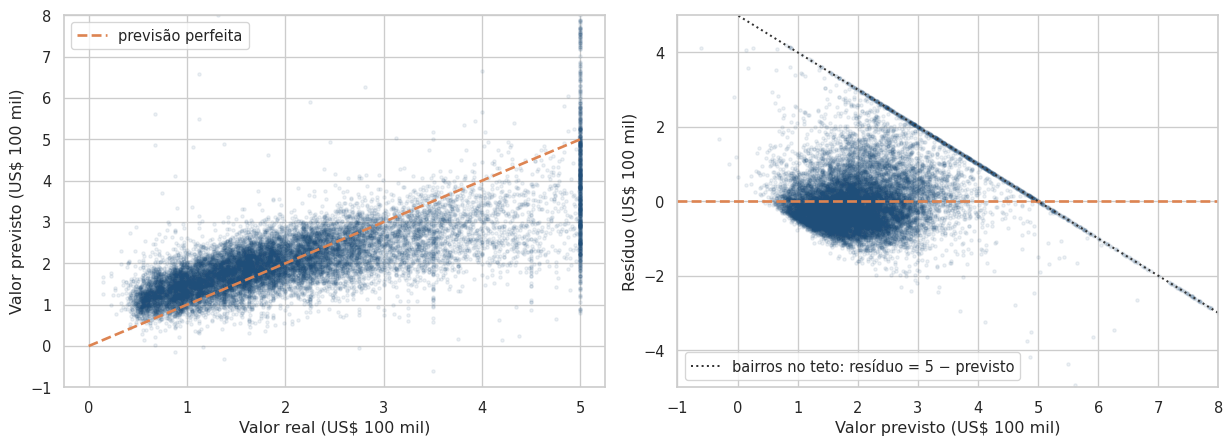

In [27]:
# Valor real versus previsto e resíduos versus previsto
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].scatter(y_dev, oof_m2, color="#1F4E79", alpha=0.08, s=6)
axes[0].plot([0, 5], [0, 5], color="#DD8452", linestyle="--", linewidth=2,
             label="previsão perfeita")
axes[0].set(xlabel="Valor real (US$ 100 mil)", ylabel="Valor previsto (US$ 100 mil)",
            ylim=(-1, 8))
axes[0].legend(loc="upper left")

axes[1].scatter(oof_m2, residuals_m2, color="#1F4E79", alpha=0.08, s=6)
axes[1].axhline(0, color="#DD8452", linestyle="--", linewidth=2)
predicted_grid = np.linspace(-1, 8, 100)
axes[1].plot(predicted_grid, 5 - predicted_grid, color="#333333", linestyle=":",
             linewidth=1.5,
             label="bairros no teto: resíduo = 5 − previsto")
axes[1].set(xlabel="Valor previsto (US$ 100 mil)", ylabel="Resíduo (US$ 100 mil)",
            xlim=(-1, 8), ylim=(-5, 5))
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

Um modelo bem especificado deixaria os resíduos como uma nuvem sem
forma, centrada em zero e de largura constante. Não é o que aparece
aqui.

No painel da esquerda, os bairros com valor real 5,0 formam uma coluna
vertical. O modelo prevê entre 1 e 7 para bairros que, nos dados, valem
todos “5,0 ou mais”. No painel da direita, esses mesmos bairros formam a
faixa diagonal pontilhada. O modelo não sabe que existe um teto, e a
censura distorce o ajuste.

Há também previsões impossíveis. O modelo linear não tem limites: alguns
bairros recebem valor previsto negativo, e quase 200 ficam acima de 5,0,
chegando a 8,0. A nuvem de resíduos também se alarga à medida que o
valor previsto cresce, e bairros caros são previstos com menos precisão
que bairros baratos. A premissa de variância constante, a
homocedasticidade, não vale aqui. Por fim, as previsões são puxadas para
a média. Os bairros mais baratos ficam, em geral, acima da linha de
previsão perfeita, e os mais caros, abaixo dela: o modelo superestima os
baratos e subestima os caros.

Nada disso invalida o M2 como previsor, já que ele erra menos que o M1
em dados novos. Os problemas apontam onde há espaço para melhorar, por
exemplo, transformando a resposta com log, tratando os bairros
censurados ou usando modelos mais flexíveis, que aparecem nas próximas
aulas.

## 5.4 A avaliação final no teste cego

O M2 venceu na validação cruzada, e só agora abrimos o teste cego. São
dois passos. Primeiro, retreinamos cada modelo com todo o
desenvolvimento, porque já não há motivo para deixar uma dobra de fora.
Depois, avaliamos uma única vez no teste:

In [28]:
# Ajuste final no desenvolvimento inteiro e previsões no teste cego
final_models = {"M1": (["MedInc"], cv_m1), "M2": (features_m2, cv_m2)}

test_predictions = {
    name: LinearRegression().fit(X_dev[cols], y_dev).predict(X_test[cols])
    for name, (cols, _) in final_models.items()
}

In [29]:
# Desempenho na validação cruzada e no teste cego, lado a lado
final_results = (
    pd.DataFrame(
        {
            name: {
                "R² (CV)": cv["test_r2"].mean(),
                "R² (teste)": r2_score(y_test, test_predictions[name]),
                "RMSE (CV)": -cv["test_rmse"].mean(),
                "RMSE (teste)": root_mean_squared_error(y_test, test_predictions[name]),
                "MAE (teste)": mean_absolute_error(y_test, test_predictions[name]),
            }
            for name, (_, cv) in final_models.items()
        }
    )
    .T
    .rename_axis("modelo")
    .round(4)
)

final_results

No teste cego, o ganho do M2 se mantém: $R^2$ de 0,51 contra 0,46, e
RMSE de 0,80 contra 0,84. Os dois modelos vão um pouco pior no teste do
que na validação cruzada, com o $R^2$ caindo entre 1,4 e 1,8
desvio-padrão das dobras. A diferença é esperada. O teste é uma única
amostra de 4.128 bairros, com a sua própria dose de acaso, e nenhuma
estimativa de erro é exata.

O que deixamos de fazer agora pesa tanto quanto o que fizemos. Se o M2
tivesse ido mal no teste, a tentação seria voltar, mudar os atributos e
testar de novo. A partir daí, porém, o teste deixaria de ser cego e
viraria só mais uma dobra de validação. O número do teste é o resultado
a reportar, seja ele bom ou ruim.

O protocolo inteiro cabe em uma frase: separe o teste antes de olhar os
dados, escolha o modelo pela validação cruzada e abra o teste uma única
vez, no fim.

# 6. Além dos mínimos quadrados

Esta seção apresenta, sem exemplos práticos, duas extensões da regressão
linear. A primeira é a regularização, uma das ideias mais gerais do
aprendizado de máquina. A segunda reúne famílias de modelos para outros
tipos de resposta.

## 6.1 Regularização

No M2, a multicolinearidade entre cômodos e quartos produziu
coeficientes grandes, de sinais opostos e instáveis. O problema se
agrava quando há muitos atributos correlacionados ou mais atributos do
que observações. O OLS ajusta então coeficientes enormes que se
compensam, e o modelo passa a decorar o ruído, como a curva flexível dos
20 bairros. O OLS só tem um objetivo: errar o mínimo possível nos dados
de treino. Nada o impede de usar toda a flexibilidade disponível para
isso.

A **regularização** muda esse objetivo. Ela acrescenta ao critério de
mínimos quadrados uma **penalidade** pelo tamanho dos coeficientes, e o
modelo passa a buscar um equilíbrio entre errar pouco e ter coeficientes
pequenos. Um coeficiente só cresce se a redução no erro compensar o que
ele paga na penalidade.

| Método | Critério minimizado | Efeito nos coeficientes |
|------------------------|------------------------|------------------------|
| OLS | $\sum e_i^2$ | Nenhuma restrição |
| Ridge (L2) | $\sum e_i^2 + \lambda \sum \beta_j^2$ | Encolhe todos em direção a zero, sem zerar nenhum |
| Lasso (L1) | $\sum e_i^2 + \lambda \sum \lvert\beta_j\rvert$ | Encolhe e zera os menos úteis: seleciona atributos |
| ElasticNet | $\sum e_i^2 + \lambda \left[\alpha \sum \lvert\beta_j\rvert + \frac{1 - \alpha}{2} \sum \beta_j^2\right]$ | Combina os dois. Mantém juntos atributos correlacionados |

A força da penalidade é controlada por $\lambda$, chamado `alpha` no
scikit-learn, que funciona como um botão de complexidade. Com
$\lambda = 0$, voltamos ao OLS. Com $\lambda$ muito grande, todos os
coeficientes vão a zero, e o modelo prevê sempre a média, como o
`DummyRegressor`. Entre um extremo e outro, $\lambda$ regula quanta
flexibilidade o modelo pode usar. Quem define $\lambda$ é quem constrói
o modelo, e não o ajuste. Por isso ele é um **hiperparâmetro**, e o seu
valor é escolhido pela validação cruzada.

A penalidade puxa os coeficientes para zero mesmo quando o valor
verdadeiro não é zero, o que introduz um pouco de viés. Em troca, os
coeficientes variam menos de uma amostra para outra, e a variância cai.
Num modelo com sobreajuste, essa troca diminui o erro em dados novos. É
o dilema viés-variância, agora com um controle explícito.

Ridge e Lasso diferem na forma da penalidade. A L2 cresce com o quadrado
do coeficiente, de modo que coeficientes grandes ficam muito caros e os
pequenos saem quase de graça. Por isso o Ridge encolhe todos, mas
raramente leva algum exatamente a zero. A L1 cresce linearmente: cada
unidade de coeficiente custa o mesmo, seja a primeira ou a última. Para
um atributo pouco útil, sai mais barato zerar o coeficiente de vez, e o
Lasso acaba fazendo uma seleção de atributos dentro do próprio ajuste.
Diante de um par muito correlacionado, como cômodos e quartos, o Lasso
tende a ficar com um e descartar o outro, enquanto o Ridge divide o peso
entre os dois. O ElasticNet combina as duas penalidades e obtém a
seleção do Lasso sem a escolha arbitrária dentro de grupos
correlacionados.

O intercepto $\beta_0$ não é penalizado. Como a penalidade soma os
tamanhos dos coeficientes, os atributos precisam estar na mesma escala.
Sem padronização, um atributo medido em pessoas, como `Population`, e
outro medido em cômodos seriam penalizados de forma desigual. A
regularização vem sempre depois de um `StandardScaler`, dentro de uma
*pipeline*. Assim, em cada dobra da validação cruzada, a média e o
desvio-padrão da padronização são aprendidos só no treino daquela dobra:
é a regra contra o vazamento, aplicada automaticamente.

E neste problema? Com 16.512 bairros e só seis atributos, o OLS já é
estável, como mostrou o feixe de retas das dobras. Não sobra variância
para a penalidade reduzir, e a regularização teria pouco a ganhar em
previsão. Ela faz diferença quando há muitos atributos em relação ao
número de observações, ou quando o modelo é flexível o bastante para
decorar os dados. Nos modelos que vêm a seguir no curso, essas situações
são a regra, e não a exceção.

> **A leitura bayesiana da regularização**
>
> As penalidades têm uma leitura probabilística. Na estatística
> bayesiana, antes de ver os dados, atribuímos aos coeficientes uma
> distribuição a priori, que expressa o que acreditamos sobre eles. O
> ajuste combina essa crença com os dados.
>
> O Ridge equivale a supor, a priori, que cada coeficiente segue uma
> normal centrada em zero, ou seja, que coeficientes grandes são
> improváveis. O Lasso equivale a supor uma distribuição de Laplace
> centrada em zero, com um pico agudo na origem. A crença, nesse caso, é
> que muitos coeficientes são exatamente zero, e é esse pico que produz
> os coeficientes nulos.
>
> Nos dois casos, quanto maior $\lambda$, mais concentrada em torno de
> zero fica a priori, e mais os dados precisam “provar” que um
> coeficiente merece ser grande.

### A mesma ideia em outros modelos de IA

Ridge e Lasso são a porta de entrada para uma ideia que atravessa o
aprendizado de máquina inteiro: penalizar a complexidade para ganhar
generalização. Em sentido amplo, chama-se regularização qualquer
restrição imposta ao modelo para reduzir o sobreajuste. De um modelo
para outro, o que muda é o que se penaliza.

A regressão logística, que aparece nas aulas de classificação, também
tem coeficientes, e a eles se aplicam as mesmas penalidades L1 e L2. Há
uma armadilha prática: no scikit-learn, a `LogisticRegression` já aplica
a penalidade L2 por padrão. A força é controlada pelo hiperparâmetro
`C`, o inverso de $\lambda$, e um `C` pequeno significa regularização
forte. Quem não sabe disso ajusta um modelo regularizado sem perceber e,
se os atributos não estiverem padronizados, penaliza-os de forma
desigual. As máquinas de vetores de suporte (SVM) funcionam do mesmo
jeito: maximizar a margem entre as classes equivale a uma penalidade L2
sobre os pesos, também controlada por um `C`.

Uma árvore de decisão não tem coeficientes, mas tem uma medida natural
de complexidade, o número de divisões e de folhas. Sem limites, ela
cresce até ter uma folha para cada observação e decora os dados, como a
curva flexível dos 20 bairros. A regularização entra como limite ao
crescimento, com uma profundidade máxima ou um número mínimo de
observações por folha, ou como **poda por custo-complexidade**, que
minimiza o erro mais $\alpha$ vezes o número de folhas. É a mesma
estrutura de erro mais penalidade do Ridge e do Lasso. Os modelos de
*gradient boosting*, como o XGBoost e o LightGBM, estão entre os mais
usados em dados tabulares e vão além. O critério de ajuste deles inclui
penalidades L1 e L2 sobre os valores previstos em cada folha e um custo
por folha criada.

Uma rede neural moderna tem de milhões a centenas de bilhões de
parâmetros, muitas vezes mais parâmetros do que observações de treino.
Sem regularização, a capacidade de decorar seria enorme. Nas redes, a
penalidade L2 ganha o nome de ***weight decay***, decaimento dos pesos.
O treino acontece aos poucos, por descida do gradiente: a cada iteração,
cada peso $w$ é ajustado na direção contrária ao gradiente do erro, com
um passo de tamanho $\eta$. Somar a penalidade $\lambda w^2$ ao erro
acrescenta um termo à atualização:

$$
w \leftarrow w - \eta\,(\nabla_w \text{erro} + \lambda w) = (1 - \eta\lambda)\,w - \eta\,\nabla_w \text{erro}
$$

A cada passo, todo peso é multiplicado por um número um pouco menor que
1 antes de ser corrigido pelo erro. Pesos que o erro não “defende”
decaem até perto de zero. O otimizador AdamW, padrão no treino de
*Transformers* e de grandes modelos de linguagem, aplica exatamente esse
decaimento.

As redes também usam regularizações que não aparecem como penalidade na
fórmula, mas cumprem o mesmo papel. O *dropout* desliga ao acaso uma
fração dos neurônios a cada passo do treino. Sem poder depender de
nenhum neurônio isolado, a rede aprende representações redundantes e
mais robustas. A parada antecipada (*early stopping*) acompanha o erro
de validação durante o treino e o interrompe quando esse erro para de
cair. É o sobreajuste visto ao longo do tempo: o erro de treino cai
sempre, e o de validação, a partir de certo ponto, sobe. No aumento de
dados (*data augmentation*), o treino de um modelo de imagens inclui,
por exemplo, versões giradas, espelhadas ou recortadas das mesmas fotos.
O modelo vê mais variações do padrão e tem menos chance de decorar
detalhes irrelevantes.

Em genômica, é comum medir dezenas de milhares de genes em algumas
centenas de pacientes. Com mais atributos do que observações, o OLS nem
tem solução única, já que infinitas combinações de coeficientes
reproduzem o treino perfeitamente. O Lasso e o ElasticNet tornam o
problema solúvel e ainda selecionam um pequeno conjunto de genes
associados ao desfecho. O mesmo vale para textos representados por
contagens de milhares de palavras. A esparsidade do L1 inspira também a
poda de redes neurais, que zera pesos pouco importantes para obter
modelos menores e mais rápidos.

A tabela reúne o que cada modelo penaliza:

| Modelo | O que é penalizado ou restringido | Hiperparâmetros típicos |
|------------------------|------------------------|------------------------|
| Ridge, Lasso, ElasticNet | Tamanho dos coeficientes | `alpha`, `l1_ratio` |
| Regressão logística | Tamanho dos coeficientes (L2 por padrão) | `C` $= 1/\lambda$, `penalty` |
| SVM | Tamanho dos pesos, por meio da margem | `C` |
| Árvore de decisão | Número de divisões e de folhas | `max_depth`, `min_samples_leaf`, `ccp_alpha` |
| *Gradient boosting* | Valores das folhas e número de folhas | `reg_lambda`, `reg_alpha`, `gamma` |
| Redes neurais | Tamanho dos pesos, neurônios ativos, duração do treino | `weight_decay`, taxa de *dropout*, paciência do *early stopping* |

Os nomes mudam de uma biblioteca para outra. Diante de qualquer um
desses hiperparâmetros, porém, a pergunta é a mesma: o que ele penaliza,
e em que direção aumenta a regularização? Em quase todos, o valor ideal
sai como aqui, da validação cruzada, sem tocar no teste cego.

## 6.2 Outras famílias de regressão

A regressão linear supõe uma resposta contínua e mede o erro pelo
quadrado dos resíduos. Quando a resposta ou a pergunta é de outra
natureza, outras famílias de modelos se encaixam melhor.

A regressão polinomial inclui potências dos atributos, como $x^2$ e
$x^3$, para captar curvas. O modelo continua linear nos coeficientes e é
ajustado por mínimos quadrados. Graus altos trazem o risco do
sobreajuste: a curva oscila e dispara nas bordas, o chamado **fenômeno
de Runge**. Na prática, raramente se passa do grau 2 ou 3.

Com contagens, como o número de acidentes em um cruzamento ou de visitas
a uma página, uma regressão linear poderia prever −2 acidentes. A
**regressão de Poisson** modela o log da média,
$\log(\mu_i) = \beta_0 + \beta_1 x_i$, e só dá previsões positivas. Ela
supõe que a variância da contagem é igual à sua média. Quando a
variância é bem maior que a média, a chamada **sobredispersão**, comum
em dados reais, a **regressão binomial negativa** acrescenta um
parâmetro que acomoda essa variância extra.

A **regressão quantílica** modela um quantil de $y$, como a mediana ou o
percentil 90, em vez da média. Assim como a mediana comum, a mediana
condicional é menos sensível a valores extremos, e quantis altos ou
baixos descrevem o risco nas caudas. Com resíduos heterocedásticos, como
os do M2, as retas de quantis diferentes têm inclinações diferentes, e a
regressão quantílica mostra isso diretamente.

Poisson e binomial negativa pertencem aos **modelos lineares
generalizados** (GLM), que estendem a regressão linear a respostas com
outras distribuições. O GLM mais conhecido é a regressão logística, para
respostas binárias, que faz a ponte para os problemas de classificação.

# Síntese

1.  A reta de mínimos quadrados minimiza a soma dos quadrados dos
    resíduos, e a sua inclinação é a correlação convertida para as
    unidades dos dados, $\beta_1 = r \cdot s_y / s_x$.
2.  Na regressão múltipla, cada coeficiente é uma associação
    condicional, válida com os demais atributos constantes. A
    multicolinearidade pode inverter sinais sem prejudicar as previsões.
3.  O erro de treino é otimista. Ele sempre premia o modelo mais
    flexível, e o sobreajuste só aparece em dados que o modelo não viu.
4.  O teste cego vem primeiro, a validação cruzada escolhe o modelo, e o
    teste é aberto uma vez, no fim. Usar as mesmas dobras em todos os
    modelos torna a comparação pareada.
5.  Os resíduos mostram onde o modelo erra. Nesta base, censura,
    previsões impossíveis e heterocedasticidade expõem os limites da
    regressão linear.
6.  A regularização penaliza a complexidade para ganhar generalização,
    trocando um pouco de viés por menos variância. A mesma ideia
    reaparece, com outros nomes, na regressão logística, nas árvores e
    nas redes neurais.

# Perguntas para consolidar

**Pergunta 1: um $R^2$ de 0,48 é bom ou ruim?**

O M1 explica cerca de 48% da variação do valor das casas. Esse modelo é
bom?

> **Como pensar sobre isso**
>
> Depende da pergunta e da referência. Comparado a prever sempre a
> média, o M1 reduz o erro típico de US\$ 116 mil para US\$ 84 mil, uma
> melhora real. Para um banco que precisa avaliar um imóvel individual,
> porém, errar US\$ 84 mil em casas de US\$ 200 mil é demais. Não existe
> um limite universal de $R^2$ “bom”: em física, 0,48 seria um fracasso;
> em ciências sociais, pode ser um ótimo resultado. Compare sempre com
> um modelo de referência e traduza o erro para a unidade do problema,
> com o MAE ou o RMSE.

**Pergunta 2: por que não escolher o modelo pelo teste cego?**

O teste cego é a avaliação mais honesta que temos. Por que não usá-lo
para decidir entre o M1 e o M2?

> **Como pensar sobre isso**
>
> Porque, no momento em que decide, o teste passa a fazer parte do
> ajuste. Com dois modelos, o efeito é pequeno. Com dezenas de modelos e
> hiperparâmetros, quem escolhe o melhor no teste escolhe, em parte, o
> que teve sorte naqueles bairros, e o erro reportado sai otimista. É o
> problema dos múltiplos testes. A validação cruzada faz as escolhas; o
> teste só mede o resultado final.

**Pergunta 3: mais cômodos desvalorizam as casas?**

No M2, o coeficiente de `AveRooms` é negativo. Um corretor deveria
aconselhar os proprietários a juntar cômodos para valorizar o imóvel?

> **Como pensar sobre isso**
>
> Não. O coeficiente compara bairros com a mesma renda, a mesma média de
> quartos e os mesmos demais atributos, uma situação rara, porque
> cômodos e quartos crescem juntos. Ele mede uma associação condicional
> e instável, causada em boa parte pela multicolinearidade, e não o
> efeito de uma reforma. Os dados, além do mais, são de bairros, e não
> de casas individuais. Coeficientes de um modelo preditivo não
> autorizam conclusões causais.

**Pergunta 4: o $R^2$ de treino sempre aumenta com mais atributos?**

O $R^2$ de treino do M2 é maior que o do M1. Se acrescentássemos ao M2
uma coluna de números aleatórios, o que aconteceria com o $R^2$ de
treino? E com o de validação?

> **Como pensar sobre isso**
>
> O $R^2$ de treino nunca diminui quando se acrescenta um atributo. No
> pior caso, o OLS dá a ele coeficiente zero e mantém o mesmo ajuste. Na
> prática, o coeficiente do ruído sai um pouco diferente de zero, e o
> $R^2$ de treino sobe levemente. O de validação, por outro lado, tende
> a cair um pouco, porque o modelo aprendeu um padrão que não se repete.
> É o sobreajuste em miniatura, e é por isso que o erro de treino não
> serve para escolher atributos.

# Para casa

1.  Construa o M3, acrescentando `Latitude` e `Longitude` ao M2, e
    avalie-o nas mesmas cinco dobras. O ganho em relação ao M2 é maior
    ou menor que o do M2 em relação ao M1? Por que a localização
    ajudaria a prever o valor das casas?
2.  Aplique o log a `Population` e `AveOccup` e repita a validação
    cruzada do M2. As métricas melhoram? Lembre-se de criar as colunas
    transformadas tanto no desenvolvimento quanto no teste.
3.  Repita a validação cruzada do M1 com 10 dobras e com outro
    `random_state`. O que muda na média e no desvio-padrão do $R^2$?
4.  Antes de considerar o notebook pronto, use Restart Kernel and Run
    All.

## Referências

1.  James, G.; Witten, D.; Hastie, T.; Tibshirani, R. *An Introduction
    to Statistical Learning: with Applications in Python*. Springer,
    2023.
2.  Hastie, T.; Tibshirani, R.; Friedman, J. *The Elements of
    Statistical Learning*. 2. ed. Springer, 2009.
3.  Pace, R. K.; Barry, R. Sparse spatial autoregressions. *Statistics &
    Probability Letters*, 33(3), 291-297, 1997.
4.  Hoerl, A. E.; Kennard, R. W. Ridge regression: biased estimation for
    nonorthogonal problems. *Technometrics*, 12(1), 55-67, 1970.
5.  Tibshirani, R. Regression shrinkage and selection via the lasso.
    *Journal of the Royal Statistical Society: Series B*, 58(1),
    267-288, 1996.
6.  Zou, H.; Hastie, T. Regularization and variable selection via the
    elastic net. *Journal of the Royal Statistical Society: Series B*,
    67(2), 301-320, 2005.
7.  Srivastava, N.; Hinton, G.; Krizhevsky, A.; Sutskever, I.;
    Salakhutdinov, R. Dropout: a simple way to prevent neural networks
    from overfitting. *Journal of Machine Learning Research*, 15,
    1929-1958, 2014.
8.  Loshchilov, I.; Hutter, F. Decoupled weight decay regularization.
    *International Conference on Learning Representations (ICLR)*, 2019.
9.  Bruce, P.; Bruce, A.; Gedeck, P. *Practical Statistics for Data
    Scientists*. 2. ed. O’Reilly, 2020.